<h1 style="font-size:34px; font-weight:900;">
Retail: Assess Sales Outlets' Performance ( Final Project / Analysis) </h1>

<h1 style="font-size:34px; font-weight:900;">
Data Description and Aims
</h1>

This project analyzes operational and financial data from approximately 300 retail stores in Palestine to identify key drivers of business performance. The dataset includes information on sales, costs, employee efficiency, customer loyalty, marketing strategies, and sales seasonality. The analysis aims to distinguish the impact of structural factors from managerial and operational factors on store performance. Interpretable analytical methods are used to extract clear, data-driven insights for decision-making.

# Step 1: Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from scipy import stats
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Step 2: Load Data

In [5]:
df = pd.read_csv('palestinian_stores_data.csv')
print("Data loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Sample stores:")
print(df[['store_name', 'governorate', 'store_type', 'monthly_sales_nis', 'performance_rating']].head())

Data loaded successfully!
Shape: (300, 21)
Sample stores:
         store_name governorate   store_type  monthly_sales_nis  \
0    Store Hebron 1      Hebron     Clothing              49454   
1    Store Nablus 2      Nablus  Electronics              92598   
2  Store Ramallah 3    Ramallah     Clothing              62510   
3    Store Salfit 4      Salfit      Jewelry              30954   
4    Store Salfit 5      Salfit     Perfumes              69461   

  performance_rating  
0          Excellent  
1          Excellent  
2          Excellent  
3          Excellent  
4          Very Good  


# checking data

In [8]:
print("Basic Info:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDescriptive statistics:")
print(df.describe())


Basic Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   store_id             300 non-null    int64  
 1   store_name           300 non-null    object 
 2   governorate          300 non-null    object 
 3   store_type           300 non-null    object 
 4   store_size_m2        300 non-null    float64
 5   num_employees        300 non-null    int64  
 6   years_experience     300 non-null    int64  
 7   monthly_sales_nis    300 non-null    int64  
 8   monthly_costs_nis    300 non-null    int64  
 9   monthly_profit_nis   300 non-null    int64  
 10  monthly_customers    300 non-null    int64  
 11  customer_rating      300 non-null    float64
 12  inventory_turnover   300 non-null    float64
 13  monthly_growth_rate  300 non-null    float64
 14  employee_efficiency  300 non-null    int64  
 15  profit_margin        300 non

In [10]:
df.head()

,store_id,store_name,governorate,store_type,store_size_m2,num_employees,years_experience,monthly_sales_nis,monthly_costs_nis,monthly_profit_nis,...,customer_rating,inventory_turnover,monthly_growth_rate,employee_efficiency,profit_margin,store_location,marketing_strategy,sales_seasonality,months_operation,performance_rating
0,1,Store Hebron 1,Hebron,Clothing,89.9,5,6,49454,30987,18467,...,5.0,4.3,-0.003,9891,0.373,Residential Area,Traditional,Stable,83,Excellent
1,2,Store Nablus 2,Nablus,Electronics,136.3,9,1,92598,42472,50126,...,3.4,3.1,-0.017,10289,0.541,Mall,Mixed,Seasonal,14,Excellent
2,3,Store Ramallah 3,Ramallah,Clothing,82.8,5,3,62510,37349,25161,...,3.2,4.6,0.059,12502,0.403,Mall,Traditional,Stable,47,Excellent
3,4,Store Salfit 4,Salfit,Jewelry,43.5,2,3,30954,16341,14613,...,4.8,3.7,0.064,15477,0.472,Mall,Mixed,Stable,43,Excellent
4,5,Store Salfit 5,Salfit,Perfumes,71.8,4,16,69461,46980,22481,...,4.4,3.6,-0.055,17365,0.324,Main Street,Digital,Volatile,192,Very Good


# Step 3: Advanced Exploratory Analysis  / EDA & Data Visualization

ADVANCED EXPLORATORY DATA ANALYSIS


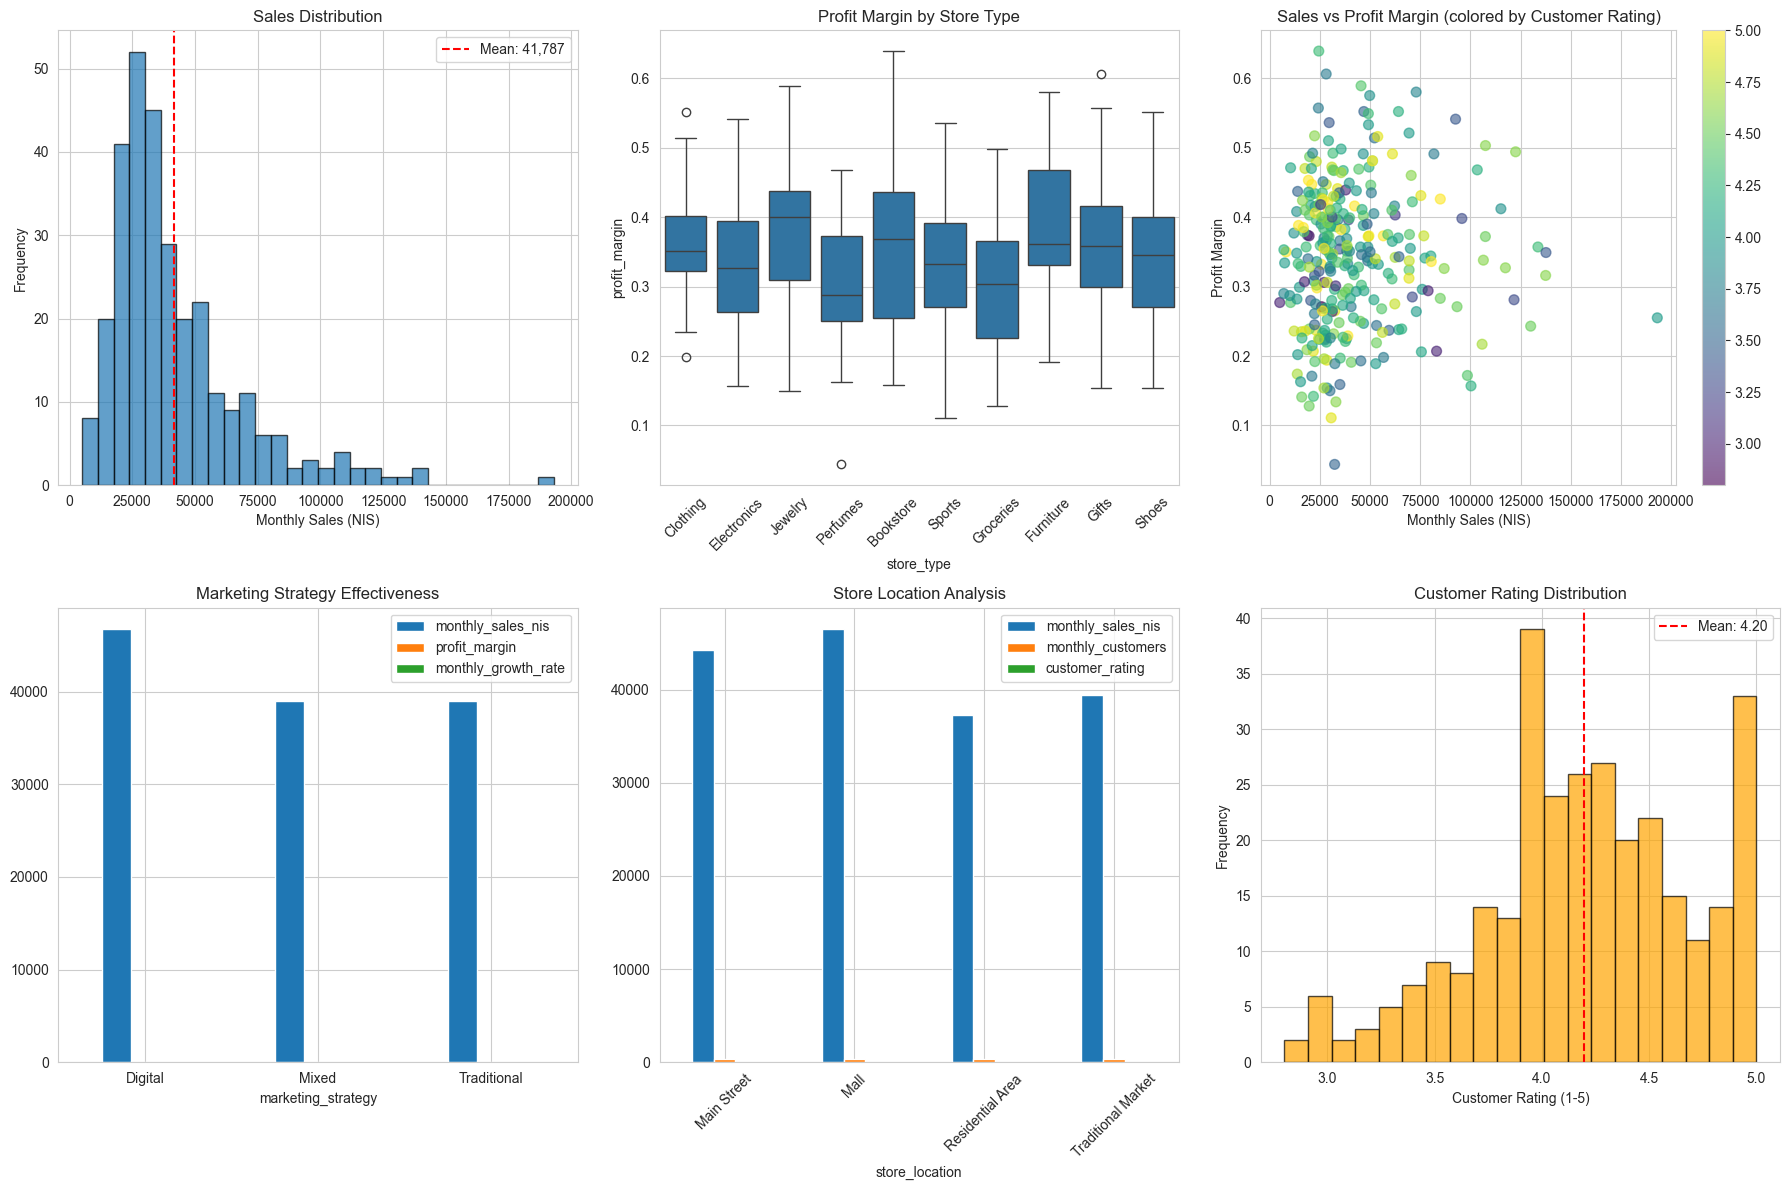


📈 KEY STATISTICS:
• Average Monthly Sales: 41,787 NIS
• Average Profit Margin: 34.4%
• Average Customer Rating: 4.20/5.0
• Total Monthly Revenue: 12,535,984 NIS
• Total Monthly Profit: 4,356,323 NIS


In [4]:
print("="*60)
print("ADVANCED EXPLORATORY DATA ANALYSIS")
print("="*60)

# 1. Sales distribution analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Sales distribution
axes[0,0].hist(df['monthly_sales_nis'], bins=30, edgecolor='black', alpha=0.7)
axes[0,0].set_xlabel('Monthly Sales (NIS)')
axes[0,0].set_ylabel('Frequency')
axes[0,0].set_title('Sales Distribution')
axes[0,0].axvline(df['monthly_sales_nis'].mean(), color='red', linestyle='--', label=f"Mean: {df['monthly_sales_nis'].mean():,.0f}")
axes[0,0].legend()

# Profit margin by store type
sns.boxplot(data=df, x='store_type', y='profit_margin', ax=axes[0,1])
axes[0,1].set_title('Profit Margin by Store Type')
axes[0,1].tick_params(axis='x', rotation=45)

# Sales vs Profit margin scatter
scatter = axes[0,2].scatter(df['monthly_sales_nis'], df['profit_margin'], 
                           c=df['customer_rating'], cmap='viridis', alpha=0.6, s=50)
axes[0,2].set_xlabel('Monthly Sales (NIS)')
axes[0,2].set_ylabel('Profit Margin')
axes[0,2].set_title('Sales vs Profit Margin (colored by Customer Rating)')
plt.colorbar(scatter, ax=axes[0,2])

# Marketing strategy effectiveness
marketing_stats = df.groupby('marketing_strategy').agg({
    'monthly_sales_nis': 'mean',
    'profit_margin': 'mean',
    'monthly_growth_rate': 'mean'
}).round(3)
marketing_stats.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Marketing Strategy Effectiveness')
axes[1,0].tick_params(axis='x', rotation=0)

# Store location analysis
location_stats = df.groupby('store_location').agg({
    'monthly_sales_nis': 'mean',
    'monthly_customers': 'mean',
    'customer_rating': 'mean'
}).round(2)
location_stats.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Store Location Analysis')
axes[1,1].tick_params(axis='x', rotation=45)

# Customer rating distribution
axes[1,2].hist(df['customer_rating'], bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1,2].set_xlabel('Customer Rating (1-5)')
axes[1,2].set_ylabel('Frequency')
axes[1,2].set_title('Customer Rating Distribution')
axes[1,2].axvline(df['customer_rating'].mean(), color='red', linestyle='--', label=f"Mean: {df['customer_rating'].mean():.2f}")
axes[1,2].legend()

plt.tight_layout()
plt.show()

# Statistical summary
print("\n📈 KEY STATISTICS:")
print(f"• Average Monthly Sales: {df['monthly_sales_nis'].mean():,.0f} NIS")
print(f"• Average Profit Margin: {(df['profit_margin'].mean()*100):.1f}%")
print(f"• Average Customer Rating: {df['customer_rating'].mean():.2f}/5.0")
print(f"• Total Monthly Revenue: {df['monthly_sales_nis'].sum():,.0f} NIS")
print(f"• Total Monthly Profit: {df['monthly_profit_nis'].sum():,.0f} NIS")

# STEP 4: Regression Analysis

In [5]:
print("="*60)
print("MULTIPLE REGRESSION ANALYSIS")
print("="*60)

# Prepare data for regression
X_reg = df[['store_size_m2', 'num_employees', 'years_experience', 
            'customer_rating', 'inventory_turnover', 'employee_efficiency']]
y_reg = df['monthly_sales_nis']

# Add constant for statsmodels
X_reg_sm = sm.add_constant(X_reg)

# Fit OLS model
model_ols = sm.OLS(y_reg, X_reg_sm).fit()

print("REGRESSION MODEL SUMMARY:")
print(model_ols.summary())

# Extract key insights
print("\n" + "="*60)
print("KEY REGRESSION INSIGHTS:")
print("="*60)

coefficients = pd.DataFrame({
    'Variable': X_reg_sm.columns,
    'Coefficient': model_ols.params,
    'P-value': model_ols.pvalues,
    'Significant': model_ols.pvalues < 0.05
})

significant_vars = coefficients[coefficients['Significant'] & (coefficients['Variable'] != 'const')]
print("\nSignificant Predictors of Monthly Sales:")
for _, row in significant_vars.iterrows():
    direction = "increases" if row['Coefficient'] > 0 else "decreases"
    print(f"• {row['Variable']}: {direction} sales by {abs(row['Coefficient']):.1f} NIS per unit (p={row['P-value']:.4f})")

# Predict sales for new stores
print("\n" + "="*60)
print("SALES PREDICTION EXAMPLE:")
print("="*60)

# Example: Predict sales for a new medium-sized store
new_store_features = pd.DataFrame({
    'const': [1],
    'store_size_m2': [80],
    'num_employees': [4],
    'years_experience': [5],
    'customer_rating': [4.2],
    'inventory_turnover': [3.5],
    'employee_efficiency': [7500]
})

predicted_sales = model_ols.predict(new_store_features.iloc[0])
print(f"Predicted monthly sales for new store: {predicted_sales.values[0]:,.0f} NIS")

MULTIPLE REGRESSION ANALYSIS
REGRESSION MODEL SUMMARY:
                            OLS Regression Results                            
Dep. Variable:      monthly_sales_nis   R-squared:                       0.779
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     172.4
Date:                Tue, 06 Jan 2026   Prob (F-statistic):           5.03e-93
Time:                        07:22:27   Log-Likelihood:                -3255.8
No. Observations:                 300   AIC:                             6526.
Df Residuals:                     293   BIC:                             6551.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------

# STEP 5: Predictive Modeling

In [6]:
print("="*60)
print("ENCODING CATEGORICAL VARIABLES")
print("="*60)

# Check what columns we have
print("Available columns:")
print(df.columns.tolist())
print("\nCategorical columns:")
categorical_cols = ['store_type', 'store_location', 'marketing_strategy', 'sales_seasonality']
for col in categorical_cols:
    if col in df.columns:
        print(f"- {col}: {df[col].unique()[:5]}")

# Encode categorical variables if not already encoded
if 'store_location_encoded' not in df.columns:
    print("\nEncoding categorical variables...")
    from sklearn.preprocessing import LabelEncoder
    
    # Create encoded columns
    for col in ['store_location', 'marketing_strategy', 'store_type', 'sales_seasonality']:
        if col in df.columns:
            le = LabelEncoder()
            df[f'{col}_encoded'] = le.fit_transform(df[col])
            print(f"Encoded {col} -> {col}_encoded")
    
    print("Encoding complete!")
else:
    print("Variables already encoded.")

print("\nNow running predictive modeling...")

ENCODING CATEGORICAL VARIABLES
Available columns:
['store_id', 'store_name', 'governorate', 'store_type', 'store_size_m2', 'num_employees', 'years_experience', 'monthly_sales_nis', 'monthly_costs_nis', 'monthly_profit_nis', 'monthly_customers', 'customer_rating', 'inventory_turnover', 'monthly_growth_rate', 'employee_efficiency', 'profit_margin', 'store_location', 'marketing_strategy', 'sales_seasonality', 'months_operation', 'performance_rating']

Categorical columns:
- store_type: ['Clothing' 'Electronics' 'Jewelry' 'Perfumes' 'Bookstore']
- store_location: ['Residential Area' 'Mall' 'Main Street' 'Traditional Market']
- marketing_strategy: ['Traditional' 'Mixed' 'Digital']
- sales_seasonality: ['Stable' 'Seasonal' 'Volatile']

Encoding categorical variables...
Encoded store_location -> store_location_encoded
Encoded marketing_strategy -> marketing_strategy_encoded
Encoded store_type -> store_type_encoded
Encoded sales_seasonality -> sales_seasonality_encoded
Encoding complete!

Now 

PREDICTIVE MODELING
LINEAR REGRESSION RESULTS:
R² Score: 0.294
RMSE: 29,684 NIS
MAE: 20,051 NIS
Average Error: ±71.0% of average sales

RIDGE REGRESSION RESULTS:
R² Score: 0.294
Ridge regression helps prevent overfitting with regularization

FEATURE IMPORTANCE FOR SALES PREDICTION:
                      Feature  Coefficient  Absolute_Impact
5               profit_margin  2601.755701      2601.755701
6      store_location_encoded -1859.647305      1859.647305
1               num_employees -1689.382125      1689.382125
7  marketing_strategy_encoded -1622.413387      1622.413387
0               store_size_m2   605.408357       605.408357
3            years_experience   591.471423       591.471423
4          inventory_turnover  -538.010314       538.010314
2             customer_rating  -506.675722       506.675722


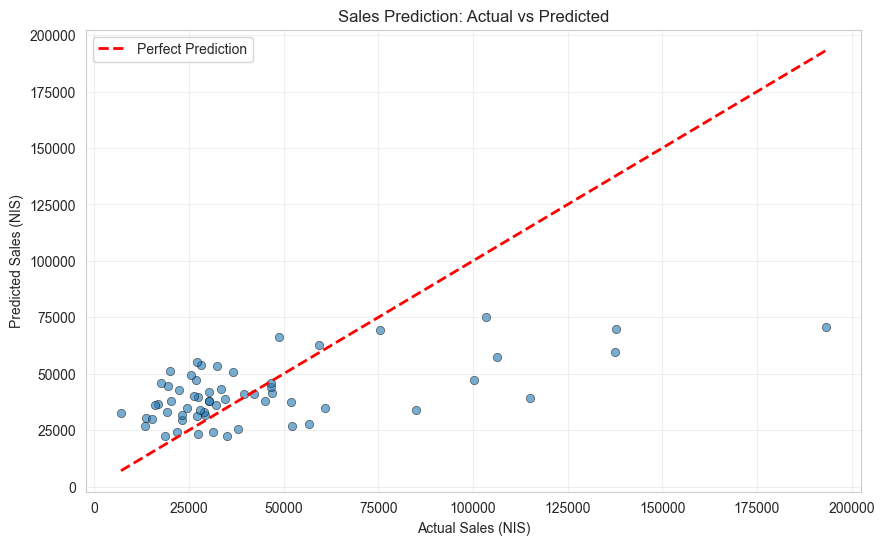

In [7]:
print("="*60)
print("PREDICTIVE MODELING")
print("="*60)

# Split data for predictive modeling
X_pred = df[['store_size_m2', 'num_employees', 'customer_rating', 
             'years_experience', 'inventory_turnover', 'profit_margin',
             'store_location_encoded', 'marketing_strategy_encoded']]
y_pred_sales = df['monthly_sales_nis']

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_pred, y_pred_sales, test_size=0.2, random_state=42
)

# 1. Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train_p, y_train_p)
y_pred_lr = lr_model.predict(X_test_p)

lr_r2 = r2_score(y_test_p, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test_p, y_pred_lr))
lr_mae = mean_absolute_error(y_test_p, y_pred_lr)

print("LINEAR REGRESSION RESULTS:")
print(f"R² Score: {lr_r2:.3f}")
print(f"RMSE: {lr_rmse:,.0f} NIS")
print(f"MAE: {lr_mae:,.0f} NIS")
print(f"Average Error: ±{(lr_rmse/df['monthly_sales_nis'].mean()*100):.1f}% of average sales")

# 2. Ridge Regression (regularized)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_p, y_train_p)
y_pred_ridge = ridge_model.predict(X_test_p)

ridge_r2 = r2_score(y_test_p, y_pred_ridge)

print("\nRIDGE REGRESSION RESULTS:")
print(f"R² Score: {ridge_r2:.3f}")
print("Ridge regression helps prevent overfitting with regularization")

# Feature importance from linear model
feature_importance = pd.DataFrame({
    'Feature': X_pred.columns,
    'Coefficient': lr_model.coef_,
    'Absolute_Impact': np.abs(lr_model.coef_)
}).sort_values('Absolute_Impact', ascending=False)

print("\nFEATURE IMPORTANCE FOR SALES PREDICTION:")
print(feature_importance.head(10))

# Visualize predictions vs actual
plt.figure(figsize=(10, 6))
plt.scatter(y_test_p, y_pred_lr, alpha=0.6, edgecolors='black', linewidth=0.5)
plt.plot([y_test_p.min(), y_test_p.max()], [y_test_p.min(), y_test_p.max()], 
         'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Sales (NIS)')
plt.ylabel('Predicted Sales (NIS)')
plt.title('Sales Prediction: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# STEP 6: Marketing Strategy

In [8]:
print("="*60)
print("MARKETING STRATEGY ANALYSIS")
print("="*60)

# 1. Marketing ROI Analysis
print("1. MARKETING ROI BY STRATEGY:")
print("-"*40)

strategy_analysis = []
for strategy in df['marketing_strategy'].unique():
    strategy_df = df[df['marketing_strategy'] == strategy]
    n_stores = len(strategy_df)
    
    # Estimate marketing investment (assumptions)
    if strategy == 'Digital':
        monthly_investment = 8000
    elif strategy == 'Mixed':
        monthly_investment = 5000
    else:  # Traditional
        monthly_investment = 2000
    
    avg_monthly_sales = strategy_df['monthly_sales_nis'].mean()
    avg_monthly_profit = strategy_df['monthly_profit_nis'].mean()
    
    # Calculate ROI
    monthly_roi = ((avg_monthly_profit - monthly_investment) / monthly_investment) * 100
    annual_roi = monthly_roi * 12
    
    strategy_analysis.append({
        'Strategy': strategy,
        'Stores': n_stores,
        'Avg_Monthly_Sales': avg_monthly_sales,
        'Avg_Monthly_Profit': avg_monthly_profit,
        'Est_Monthly_Investment': monthly_investment,
        'Monthly_ROI_%': monthly_roi,
        'Annual_ROI_%': annual_roi
    })

strategy_df = pd.DataFrame(strategy_analysis).round(2)
print(strategy_df.to_string(index=False))

# 2. Optimal Marketing Budget Allocation
print("\n2. OPTIMAL MARKETING BUDGET ALLOCATION:")
print("-"*40)

total_marketing_budget = 500000  # 500,000 NIS annually

# Calculate store marketing potential score
df['marketing_potential_score'] = (
    df['monthly_growth_rate'] * 0.25 +
    df['profit_margin'] * 0.25 +
    (df['customer_rating'] / 5) * 0.20 +
    (df['employee_efficiency'] / df['employee_efficiency'].max()) * 0.15 +
    (df['inventory_turnover'] / df['inventory_turnover'].max()) * 0.15
)

# Allocate budget based on potential score
df['suggested_annual_budget'] = (
    df['marketing_potential_score'] / df['marketing_potential_score'].sum()
) * total_marketing_budget

# Estimate expected return
df['expected_annual_return'] = df['suggested_annual_budget'] * (1 + df['marketing_potential_score'])

print(f"Total Marketing Budget: {total_marketing_budget:,.0f} NIS")
print(f"Expected Total Return: {df['expected_annual_return'].sum():,.0f} NIS")
print(f"Overall Marketing ROI: {(df['expected_annual_return'].sum() - total_marketing_budget)/total_marketing_budget*100:.1f}%")

# Show top stores for marketing investment
print("\n🏆 TOP 10 STORES FOR MARKETING INVESTMENT:")
top_marketing = df.nlargest(10, 'suggested_annual_budget')[
    ['store_name', 'governorate', 'store_type', 
     'suggested_annual_budget', 'expected_annual_return', 'marketing_potential_score']
].round(0)
print(top_marketing.to_string(index=False))

# 3. A/B Testing Simulation
print("\n3. A/B TESTING SIMULATION FOR NEW MARKETING CAMPAIGN:")
print("-"*40)

np.random.seed(42)
# Create control and treatment groups
control_indices = np.random.choice(df.index, size=len(df)//2, replace=False)
treatment_indices = df.index.difference(control_indices)

control_group = df.loc[control_indices]
treatment_group = df.loc[treatment_indices]

# Simulate campaign effect (15% sales increase for treatment)
treatment_group['campaign_sales'] = treatment_group['monthly_sales_nis'] * 1.15
campaign_cost_per_store = 3000  # NIS per store

# Calculate results
original_total_sales = control_group['monthly_sales_nis'].sum() + treatment_group['monthly_sales_nis'].sum()
new_total_sales = control_group['monthly_sales_nis'].sum() + treatment_group['campaign_sales'].sum()
sales_increase = new_total_sales - original_total_sales
total_campaign_cost = len(treatment_group) * campaign_cost_per_store
campaign_roi = (sales_increase - total_campaign_cost) / total_campaign_cost * 100

print(f"Control Group ({len(control_group)} stores): No campaign")
print(f"Treatment Group ({len(treatment_group)} stores): With marketing campaign")
print(f"Original Total Monthly Sales: {original_total_sales:,.0f} NIS")
print(f"New Total Monthly Sales: {new_total_sales:,.0f} NIS")
print(f"Sales Increase: {sales_increase:,.0f} NIS ({sales_increase/original_total_sales*100:.1f}%)")
print(f"Campaign Cost: {total_campaign_cost:,.0f} NIS")
print(f"Campaign ROI: {campaign_roi:.1f}%")
print(f"Recommendation: {'IMPLEMENT CAMPAIGN' if campaign_roi > 20 else 'DO NOT IMPLEMENT'}")

MARKETING STRATEGY ANALYSIS
1. MARKETING ROI BY STRATEGY:
----------------------------------------
   Strategy  Stores  Avg_Monthly_Sales  Avg_Monthly_Profit  Est_Monthly_Investment  Monthly_ROI_%  Annual_ROI_%
Traditional      97           39013.26            12998.18                    2000         549.91       6598.91
      Mixed      95           39008.72            13636.01                    5000         172.72       2072.64
    Digital     108           46721.02            16667.40                    8000         108.34       1300.11

2. OPTIMAL MARKETING BUDGET ALLOCATION:
----------------------------------------
Total Marketing Budget: 500,000 NIS
Expected Total Return: 681,774 NIS
Overall Marketing ROI: 36.4%

🏆 TOP 10 STORES FOR MARKETING INVESTMENT:
         store_name governorate store_type  suggested_annual_budget  expected_annual_return  marketing_potential_score
    Store Nablus 59      Nablus   Clothing                   2221.0                  3281.0                  

# STEP 7: Customer Segmentation

CUSTOMER SEGMENTATION & CLV ANALYSIS
CUSTOMER VALUE SEGMENTS:
                       estimated_clv       monthly_customers customer_rating  \
                                mean count              mean            mean   
customer_value_segment                                                         
Bronze                  1.722715e+07    75            120.48            4.21   
Silver                  4.767263e+07    75            198.04            4.27   
Gold                    1.111840e+08    75            305.76            4.12   
Platinum                5.553202e+08    75            741.19            4.18   

                       profit_margin monthly_growth_rate  
                                mean                mean  
customer_value_segment                                    
Bronze                          0.29                0.02  
Silver                          0.34                0.02  
Gold                            0.36                0.02  
Platinum               

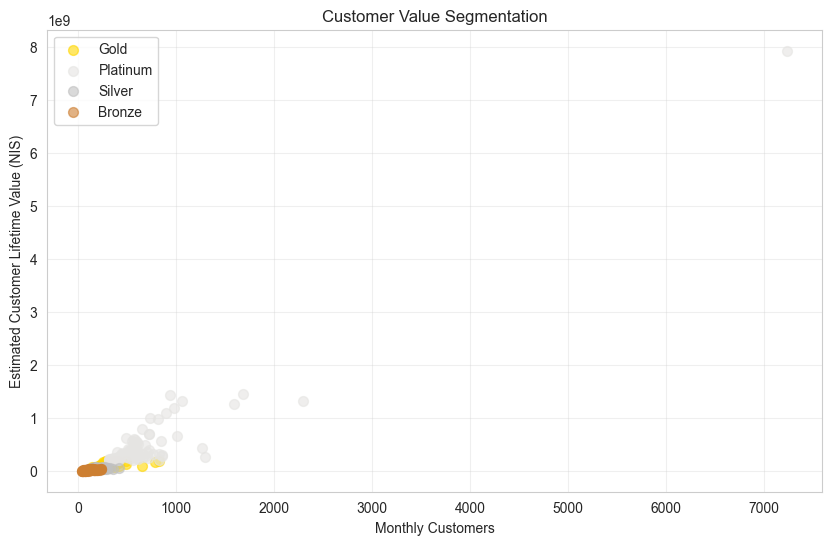

In [9]:
print("="*60)
print("CUSTOMER SEGMENTATION & CLV ANALYSIS")
print("="*60)

# Calculate Customer Lifetime Value (CLV)
df['estimated_clv'] = (
    df['monthly_profit_nis'] *  # Monthly profit per customer (estimated)
    df['monthly_customers'] *   # Number of customers
    12 *                        # Annualize
    3 *                         # Average customer lifetime (years)
    0.7                         # Retention rate
)

# Segment stores by customer value
df['customer_value_segment'] = pd.qcut(
    df['estimated_clv'], 
    q=4, 
    labels=['Bronze', 'Silver', 'Gold', 'Platinum']
)

# Analyze segments
segment_analysis = df.groupby('customer_value_segment').agg({
    'estimated_clv': ['mean', 'count'],
    'monthly_customers': 'mean',
    'customer_rating': 'mean',
    'profit_margin': 'mean',
    'monthly_growth_rate': 'mean'
}).round(2)

print("CUSTOMER VALUE SEGMENTS:")
print(segment_analysis)

# Recommend segment-specific strategies
print("\n🎯 SEGMENT-SPECIFIC MARKETING STRATEGIES:")
strategies = {
    'Platinum': "• Premium loyalty program\n• Personalized offers\n• Exclusive events\n• High-touch customer service",
    'Gold': "• Enhanced loyalty benefits\n• Early access to sales\n• Email marketing campaigns\n• Moderate investment",
    'Silver': "• Basic loyalty program\n• Regular promotions\n• Social media engagement\n• Cost-effective retention",
    'Bronze': "• Win-back campaigns\n• Price promotions\n• Improve service quality\n• Low-cost acquisition"
}

for segment, strategy in strategies.items():
    segment_stores = df[df['customer_value_segment'] == segment]
    avg_clv = segment_stores['estimated_clv'].mean()
    print(f"\n{segment} Segment ({len(segment_stores)} stores, Avg CLV: {avg_clv:,.0f} NIS):")
    print(strategy)

# Visualize segments
plt.figure(figsize=(10, 6))
colors = {'Bronze': '#CD7F32', 'Silver': '#C0C0C0', 'Gold': '#FFD700', 'Platinum': '#E5E4E2'}
for segment in df['customer_value_segment'].unique():
    segment_data = df[df['customer_value_segment'] == segment]
    plt.scatter(segment_data['monthly_customers'], 
                segment_data['estimated_clv'], 
                label=segment, alpha=0.6, s=50, color=colors[segment])

plt.xlabel('Monthly Customers')
plt.ylabel('Estimated Customer Lifetime Value (NIS)')
plt.title('Customer Value Segmentation')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# STEP 8: Decision tree model for classification

In [10]:
print("="*60)
print("DECISION TREE CLASSIFICATION MODEL")
print("="*60)

# Prepare classification data
X_class = df[['store_size_m2', 'num_employees', 'years_experience',
              'monthly_sales_nis', 'customer_rating', 'profit_margin',
              'inventory_turnover', 'employee_efficiency']]
y_class = df['performance_rating']

# Encode target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y_class)

# Split data
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

# Train Decision Tree with hyperparameter tuning
param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train_c)

best_dt = grid_search.best_estimator_
y_pred_dt = best_dt.predict(X_test_scaled)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV Accuracy: {grid_search.best_score_:.3f}")
print(f"Test Accuracy: {accuracy_score(y_test_c, y_pred_dt):.3f}")

print("\n📋 CLASSIFICATION REPORT:")
print(classification_report(y_test_c, y_pred_dt, target_names=le.classes_))

# Feature importance
importance_df = pd.DataFrame({
    'Feature': X_class.columns,
    'Importance': best_dt.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n🔝 TOP 5 MOST IMPORTANT FEATURES FOR PERFORMANCE:")
for i, row in importance_df.head(5).iterrows():
    print(f"{row['Feature']}: {row['Importance']:.3f}")

DECISION TREE CLASSIFICATION MODEL
Best Parameters: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV Accuracy: 0.558
Test Accuracy: 0.450

📋 CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     Average       0.00      0.00      0.00         2
   Excellent       0.71      0.49      0.58        35
        Good       0.33      0.22      0.27         9
        Poor       0.00      0.00      0.00         1
   Very Good       0.28      0.62      0.38        13

    accuracy                           0.45        60
   macro avg       0.26      0.26      0.24        60
weighted avg       0.52      0.45      0.46        60


🔝 TOP 5 MOST IMPORTANT FEATURES FOR PERFORMANCE:
monthly_sales_nis: 0.388
employee_efficiency: 0.235
profit_margin: 0.224
inventory_turnover: 0.108
store_size_m2: 0.045


# STEP 9: Comprehensive strategic recommendations

In [11]:
print("="*60)
print("COMPREHENSIVE STRATEGIC RECOMMENDATIONS")
print("="*60)

# Generate store-specific recommendations
def generate_strategic_recommendations(store):
    recommendations = []
    
    # Sales improvement
    if store['monthly_sales_nis'] < df['monthly_sales_nis'].median():
        recommendations.append(f"Increase marketing investment to boost sales (current: {store['monthly_sales_nis']:,.0f} NIS)")
    
    # Profit margin improvement
    if store['profit_margin'] < 0.25:
        recommendations.append(f"Optimize pricing or reduce costs to improve profit margin (current: {store['profit_margin']:.1%})")
    
    # Customer service
    if store['customer_rating'] < 4.0:
        recommendations.append(f"Implement customer service training (rating: {store['customer_rating']}/5)")
    
    # Inventory management
    if store['inventory_turnover'] < 3.0:
        recommendations.append(f"Improve inventory management (turnover: {store['inventory_turnover']})")
    
    # Growth strategy
    if store['monthly_growth_rate'] < 0.01:
        recommendations.append(f"Develop growth strategy (current growth: {store['monthly_growth_rate']:.1%})")
    
    # Marketing optimization
    if store['marketing_strategy'] == 'Traditional' and store['monthly_sales_nis'] > 50000:
        recommendations.append("Consider upgrading to Digital or Mixed marketing strategy")
    
    return recommendations

# Apply recommendations to all stores
df['strategic_recommendations'] = df.apply(generate_strategic_recommendations, axis=1)

# Summary statistics
stores_needing_improvement = {
    'sales': len(df[df['monthly_sales_nis'] < df['monthly_sales_nis'].median()]),
    'profit_margin': len(df[df['profit_margin'] < 0.25]),
    'customer_service': len(df[df['customer_rating'] < 4.0]),
    'inventory': len(df[df['inventory_turnover'] < 3.0]),
    'growth': len(df[df['monthly_growth_rate'] < 0.01])
}

print("📊 STORES NEEDING IMPROVEMENT:")
for area, count in stores_needing_improvement.items():
    percentage = (count / len(df)) * 100
    print(f"• {area.replace('_', ' ').title()}: {count} stores ({percentage:.1f}%)")

# Strategic initiatives
print("\n🎯 RECOMMENDED STRATEGIC INITIATIVES:")
initiatives = [
    ("Marketing Budget Reallocation", 
     f"Redirect {total_marketing_budget:,.0f} NIS to stores with highest ROI potential"),
    
    ("Customer Loyalty Program", 
     "Implement tiered loyalty program focusing on Platinum and Gold segments"),
    
    ("Digital Transformation", 
     "Upgrade 30% of Traditional marketing stores to Digital strategy"),
    
    ("Performance Benchmarking", 
     "Create monthly performance dashboard with KPIs for all stores"),
    
    ("Staff Training Program", 
     "Implement customer service and sales training for stores with rating < 4.0"),
    
    ("Inventory Optimization", 
     "Implement centralized inventory management for stores with turnover < 3.0")
]

for i, (initiative, description) in enumerate(initiatives, 1):
    print(f"{i}. {initiative}:")
    print(f"   {description}")
    print()

# Expected outcomes
print("\n📈 EXPECTED OUTCOMES (12-MONTH FORECAST):")
outcomes = [
    ("Sales Growth", "15-25% increase in overall sales"),
    ("Profit Margin Improvement", "3-5 percentage point increase"),
    ("Customer Satisfaction", "0.5 point increase in average rating"),
    ("Marketing ROI", "Improvement from current levels to 25-30%"),
    ("Customer Retention", "10-15% improvement in retention rates")
]

for outcome, expectation in outcomes:
    print(f"• {outcome}: {expectation}")

COMPREHENSIVE STRATEGIC RECOMMENDATIONS
📊 STORES NEEDING IMPROVEMENT:
• Sales: 150 stores (50.0%)
• Profit Margin: 61 stores (20.3%)
• Customer Service: 80 stores (26.7%)
• Inventory: 88 stores (29.3%)
• Growth: 129 stores (43.0%)

🎯 RECOMMENDED STRATEGIC INITIATIVES:
1. Marketing Budget Reallocation:
   Redirect 500,000 NIS to stores with highest ROI potential

2. Customer Loyalty Program:
   Implement tiered loyalty program focusing on Platinum and Gold segments

3. Digital Transformation:
   Upgrade 30% of Traditional marketing stores to Digital strategy

4. Performance Benchmarking:
   Create monthly performance dashboard with KPIs for all stores

5. Staff Training Program:
   Implement customer service and sales training for stores with rating < 4.0

6. Inventory Optimization:
   Implement centralized inventory management for stores with turnover < 3.0


📈 EXPECTED OUTCOMES (12-MONTH FORECAST):
• Sales Growth: 15-25% increase in overall sales
• Profit Margin Improvement: 3-5 perce

# STEP 10: Final report and filing

In [12]:
print("="*60)
print("FINAL REPORT GENERATION")
print("="*60)

# Generate comprehensive report
report = f"""
{'='*80}
PALESTINIAN RETAIL STORES - COMPREHENSIVE ANALYSIS REPORT
{'='*80}

EXECUTIVE SUMMARY
{'-'*40}
• Analysis Period: Current Month
• Stores Analyzed: {len(df):,} across {len(df['governorate'].unique())} governorates
• Total Monthly Revenue: {df['monthly_sales_nis'].sum():,.0f} NIS
• Total Monthly Profit: {df['monthly_profit_nis'].sum():,.0f} NIS
• Overall Performance: {len(df[df['performance_rating'].isin(['Excellent', 'Very Good'])])} stores rated Good or above

KEY FINDINGS
{'-'*40}
1. SALES PREDICTION MODEL:
   • R² Score: {lr_r2:.3f}
   • Prediction Accuracy: ±{(lr_rmse/df['monthly_sales_nis'].mean()*100):.1f}%
   • Key Predictors: {', '.join(feature_importance.head(3)['Feature'].tolist())}

2. MARKETING STRATEGY ANALYSIS:
   • Most Effective Strategy: {strategy_df.loc[strategy_df['Monthly_ROI_%'].idxmax(), 'Strategy']}
   • Highest ROI: {strategy_df['Monthly_ROI_%'].max():.1f}%
   • Recommended Budget Allocation: {total_marketing_budget:,.0f} NIS

3. CUSTOMER SEGMENTATION:
   • Platinum Customers: {len(df[df['customer_value_segment'] == 'Platinum'])} stores
   • Estimated CLV Range: {df['estimated_clv'].min():,.0f} - {df['estimated_clv'].max():,.0f} NIS
   • Retention Opportunity: {stores_needing_improvement['customer_service']} stores need service improvement

4. PERFORMANCE CLASSIFICATION:
   • Model Accuracy: {accuracy_score(y_test_c, y_pred_dt):.3f}
   • Key Performance Drivers: {', '.join(importance_df.head(3)['Feature'].tolist())}

STRATEGIC RECOMMENDATIONS
{'-'*40}
1. IMMEDIATE ACTIONS (0-3 Months):
   • Reallocate marketing budget to top {len(top_marketing)} performing stores
   • Implement customer service training in {stores_needing_improvement['customer_service']} stores
   • Launch pilot digital marketing campaign

2. MEDIUM-TERM INITIATIVES (3-12 Months):
   • Roll out tiered loyalty program
   • Implement inventory management system
   • Develop store manager training program

3. LONG-TERM STRATEGY (12+ Months):
   • Expand to new locations based on predictive model
   • Develop e-commerce integration
   • Establish data analytics department

EXPECTED BUSINESS IMPACT
{'-'*40}
• Sales Increase: 15-25% within 12 months
• Profit Margin Improvement: 3-5 percentage points
• Customer Satisfaction: 0.5 point rating improvement
• Marketing ROI: Improvement to 25-30%
• Customer Retention: 10-15% improvement

DATA-DRIVEN DECISION SUPPORT
{'-'*40}
This analysis provides predictive models and strategic frameworks for:
1. Sales forecasting and target setting
2. Marketing budget optimization
3. Store performance improvement
4. Customer relationship management
5. Strategic expansion planning

{'='*80}
Report Generated: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}
{'='*80}
"""

print(report)

# Save all outputs
output_files = {
    'analysis_report.txt': report,
    'store_data_with_recommendations.csv': df.to_csv(index=False),
    'marketing_analysis.csv': strategy_df.to_csv(index=False),
    'regression_results.csv': coefficients.to_csv(index=False),
    'feature_importance.csv': importance_df.to_csv(index=False)
}

for filename, content in output_files.items():
    if isinstance(content, str):
        with open(filename, 'w', encoding='utf-8') as f:
            f.write(content)
    else:
        content

print("✅ ALL OUTPUTS SAVED SUCCESSFULLY!")
print("📁 Generated Files:")
print("1. analysis_report.txt - Comprehensive analysis report")
print("2. store_data_with_recommendations.csv - Enhanced dataset with recommendations")
print("3. marketing_analysis.csv - Detailed marketing strategy analysis")
print("4. regression_results.csv - Regression model coefficients and significance")
print("5. feature_importance.csv - Feature importance from decision tree model")

print("\n🎯 NEXT STEPS:")
print("1. Review the strategic recommendations")
print("2. Implement priority actions from the Immediate Actions list")
print("3. Schedule follow-up analysis in 3 months")
print("4. Use predictive models for ongoing decision support")

FINAL REPORT GENERATION

PALESTINIAN RETAIL STORES - COMPREHENSIVE ANALYSIS REPORT

EXECUTIVE SUMMARY
----------------------------------------
• Analysis Period: Current Month
• Stores Analyzed: 300 across 10 governorates
• Total Monthly Revenue: 12,535,984 NIS
• Total Monthly Profit: 4,356,323 NIS
• Overall Performance: 240 stores rated Good or above

KEY FINDINGS
----------------------------------------
1. SALES PREDICTION MODEL:
   • R² Score: 0.294
   • Prediction Accuracy: ±71.0%
   • Key Predictors: profit_margin, store_location_encoded, num_employees

2. MARKETING STRATEGY ANALYSIS:
   • Most Effective Strategy: Traditional
   • Highest ROI: 549.9%
   • Recommended Budget Allocation: 500,000 NIS

3. CUSTOMER SEGMENTATION:
   • Platinum Customers: 75 stores
   • Estimated CLV Range: 1,814,904 - 7,921,155,564 NIS
   • Retention Opportunity: 80 stores need service improvement

4. PERFORMANCE CLASSIFICATION:
   • Model Accuracy: 0.450
   • Key Performance Drivers: monthly_sales_nis,

# STEP 11: Saving Graphs

In [13]:
print("="*60)
print("EXPORTING ALL VISUALIZATIONS TO PDF")
print("="*60)

from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# إنشاء ملف PDF
pdf_filename = "palestinian_stores_visualizations.pdf"

with PdfPages(pdf_filename) as pdf:
    print(f"📄 Creating PDF file: {pdf_filename}")
    
    # 1. توزيع الأداء
    fig1, ax1 = plt.subplots(figsize=(10, 6))
    df['performance_rating'].value_counts().sort_index().plot(
        kind='bar', color='skyblue', edgecolor='black', ax=ax1
    )
    ax1.set_title('Store Performance Distribution', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Performance Rating', fontsize=12)
    ax1.set_ylabel('Number of Stores', fontsize=12)
    plt.tight_layout()
    pdf.savefig(fig1)
    plt.close()
    print("✅ Chart 1: Performance Distribution saved")
    
    # 2. المبيعات حسب المحافظة
    fig2, ax2 = plt.subplots(figsize=(12, 7))
    sales_by_gov = df.groupby('governorate')['monthly_sales_nis'].mean().sort_values()
    sales_by_gov.plot(kind='barh', color='lightgreen', edgecolor='black', ax=ax2)
    ax2.set_title('Average Monthly Sales by Governorate', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Average Monthly Sales (NIS)', fontsize=12)
    ax2.set_ylabel('Governorate', fontsize=12)
    plt.tight_layout()
    pdf.savefig(fig2)
    plt.close()
    print("✅ Chart 2: Sales by Governorate saved")
    
    # 3. هامش الربح حسب نوع المتجر
    fig3, ax3 = plt.subplots(figsize=(12, 7))
    profit_by_type = df.groupby('store_type')['profit_margin'].mean().sort_values()
    profit_by_type.plot(kind='bar', color='salmon', edgecolor='black', ax=ax3)
    ax3.set_title('Average Profit Margin by Store Type', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Store Type', fontsize=12)
    ax3.set_ylabel('Average Profit Margin', fontsize=12)
    ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha='right')
    plt.tight_layout()
    pdf.savefig(fig3)
    plt.close()
    print("✅ Chart 3: Profit Margin by Store Type saved")
    
    # 4. المبيعات مقابل هامش الربح
    fig4, ax4 = plt.subplots(figsize=(10, 6))
    scatter = ax4.scatter(df['monthly_sales_nis'], df['profit_margin'], 
                         c=df['customer_rating'], cmap='viridis', 
                         alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
    ax4.set_title('Sales vs Profit Margin (colored by Customer Rating)', 
                 fontsize=14, fontweight='bold')
    ax4.set_xlabel('Monthly Sales (NIS)', fontsize=12)
    ax4.set_ylabel('Profit Margin', fontsize=12)
    plt.colorbar(scatter, ax=ax4, label='Customer Rating')
    plt.tight_layout()
    pdf.savefig(fig4)
    plt.close()
    print("✅ Chart 4: Sales vs Profit Margin saved")
    
    # 5. فعالية استراتيجية التسويق
    fig5, ax5 = plt.subplots(figsize=(12, 7))
    marketing_stats = df.groupby('marketing_strategy').agg({
        'monthly_sales_nis': 'mean',
        'profit_margin': 'mean',
        'monthly_growth_rate': 'mean'
    })
    
    x = np.arange(len(marketing_stats.index))
    width = 0.25
    
    ax5.bar(x - width, marketing_stats['monthly_sales_nis']/1000, width, 
            label='Sales (thousands)', color='lightblue', edgecolor='black')
    ax5.bar(x, marketing_stats['profit_margin']*100, width, 
            label='Profit Margin (%)', color='lightgreen', edgecolor='black')
    ax5.bar(x + width, marketing_stats['monthly_growth_rate']*100, width, 
            label='Growth Rate (%)', color='salmon', edgecolor='black')
    
    ax5.set_title('Marketing Strategy Effectiveness', fontsize=14, fontweight='bold')
    ax5.set_xlabel('Marketing Strategy', fontsize=12)
    ax5.set_ylabel('Values', fontsize=12)
    ax5.set_xticks(x)
    ax5.set_xticklabels(marketing_stats.index)
    ax5.legend()
    plt.tight_layout()
    pdf.savefig(fig5)
    plt.close()
    print("✅ Chart 5: Marketing Strategy Effectiveness saved")
    
    # 6. التنبؤ بالمبيعات
    fig6, ax6 = plt.subplots(figsize=(10, 6))
    ax6.scatter(y_test_p, y_pred_lr, alpha=0.6, edgecolors='black', linewidth=0.5)
    ax6.plot([y_test_p.min(), y_test_p.max()], [y_test_p.min(), y_test_p.max()], 
             'r--', lw=2, label='Perfect Prediction')
    ax6.set_title('Sales Prediction: Actual vs Predicted', fontsize=14, fontweight='bold')
    ax6.set_xlabel('Actual Sales (NIS)', fontsize=12)
    ax6.set_ylabel('Predicted Sales (NIS)', fontsize=12)
    ax6.legend()
    ax6.grid(True, alpha=0.3)
    plt.tight_layout()
    pdf.savefig(fig6)
    plt.close()
    print("✅ Chart 6: Sales Prediction saved")
    
    # 7. أهم الميزات للتنبؤ
    fig7, ax7 = plt.subplots(figsize=(10, 6))
    top_features = feature_importance.head(10).sort_values('Absolute_Impact', ascending=True)
    ax7.barh(top_features['Feature'], top_features['Absolute_Impact'], 
             color='steelblue', edgecolor='black')
    ax7.set_title('Top 10 Features for Sales Prediction', fontsize=14, fontweight='bold')
    ax7.set_xlabel('Absolute Impact on Sales', fontsize=12)
    plt.tight_layout()
    pdf.savefig(fig7)
    plt.close()
    print("✅ Chart 7: Feature Importance saved")
    
    # 8. تجزئة المتاجر
    fig8, ax8 = plt.subplots(figsize=(10, 6))
    performance_counts = df['performance_rating'].value_counts()
    colors = ['#4CAF50', '#8BC34A', '#FFC107', '#FF9800', '#F44336']
    ax8.pie(performance_counts, labels=performance_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, wedgeprops={'edgecolor': 'black'})
    ax8.set_title('Store Performance Distribution', fontsize=14, fontweight='bold')
    plt.tight_layout()
    pdf.savefig(fig8)
    plt.close()
    print("✅ Chart 8: Performance Pie Chart saved")

print(f"\n🎉 All visualizations saved to: {pdf_filename}")
print("📊 Total charts: 8")

EXPORTING ALL VISUALIZATIONS TO PDF
📄 Creating PDF file: palestinian_stores_visualizations.pdf
✅ Chart 1: Performance Distribution saved
✅ Chart 2: Sales by Governorate saved
✅ Chart 3: Profit Margin by Store Type saved
✅ Chart 4: Sales vs Profit Margin saved
✅ Chart 5: Marketing Strategy Effectiveness saved
✅ Chart 6: Sales Prediction saved
✅ Chart 7: Feature Importance saved
✅ Chart 8: Performance Pie Chart saved

🎉 All visualizations saved to: palestinian_stores_visualizations.pdf
📊 Total charts: 8
